# Gaussian mixture model (GMM): Gini coefficients for the 7 target rules

Uses the same selected features and preprocessing as `clustering_full_dataset.ipynb` and `kmeans_gini.ipynb`. Gini here is the **Gini coefficient** (2 x AUC - 1), calculated one-vs-rest for each of the 7 target rules. Each client's score is the share of their cluster that falls under the rule. The target is never used to form the clusters.

GMMs are fitted on a reproducible sample (as in the original notebook) and then every client is assigned with `predict`. BIC is shown for each candidate so you can also compare on that.

## 1. Configuration and imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.mixture import GaussianMixture

TARGET = "target_value"
OBS_ID = "obs_id"
CUSTOMER_ID = "cifwithcheckdigit"  # set to None if unavailable

EXCLUDE_COLUMNS = {
    OBS_ID, CUSTOMER_ID, TARGET,
    "target_rule", "total_paid", "payment_count",
    "m0_monthenddate", "transactiondate",
}

RANDOM_STATE = 0
METHOD = "gmm"
COMPONENTS = [7]                       # e.g. [5, 6, 7] to compare
COVARIANCE_TYPES = ["full", "tied", "diag", "spherical"]
N_INIT = 3
GMM_TUNING_MAX_ROWS = 15000            # fit on a sample of this size, then predict on all rows
OUT_DIR = Path("gmm_gini_output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load data and select features

In [2]:
from build_dataset import load_dataset

D = load_dataset("dataset")
X_all = D["X_all"]
target_rule = D["labels"]["target_rule"]

In [3]:
keep = ['arrears_share_of_due',
 'bal7_ratio_last',
 'cash_share_of_spend',
 'committed_share_of_spend',
 'crccreditlimit_slog',
 'days_since_last_income',
 'grp_debt_repayment_share',
 'income_cv',
 'income_type_p0_rank',
 'm0_arrearsamount_slog',
 'm0_start_cd_group_CD 1',
 'm0_start_cd_group_CD 3',
 'm0_total_due_with_arrears_slog',
 'n_spend_groups_used',
 'no_complete_cycle',
 'no_income_detected',
 'no_income_seen',
 'pay_frequency_weekly',
 'product_group_NPDM',
 'recent_vs_avg_income',
 'run_grp_debt_repayment_slog',
 'run_in_income_employment_slog',
 'run_in_income_informal_slog',
 'run_income_slog',
 'run_n_bounced',
 'run_n_fees',
 'run_n_purchases',
 'run_nonessential_slog',
 'unemployed_now']

Xi = X_all[keep].copy()

## 3. Prepare predictors
Median-impute and standardise numeric columns; mode-impute and one-hot encode categoricals; drop constant columns.

In [4]:
feature_cols = [c for c in Xi.columns if c not in EXCLUDE_COLUMNS]
X_raw = Xi[feature_cols].copy()
obs_ids = Xi.reset_index()[OBS_ID]

for c in X_raw.select_dtypes(include=["bool"]).columns:
    X_raw[c] = X_raw[c].astype("int8")

numeric_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in X_raw.columns if c not in numeric_cols]
usable = lambda c: X_raw[c].notna().any() and X_raw[c].nunique(dropna=True) > 1
numeric_cols = [c for c in numeric_cols if usable(c)]
categorical_cols = [c for c in categorical_cols if usable(c)]
X_raw = X_raw[numeric_cols + categorical_cols]

transformers = []
if numeric_cols:
    transformers.append(("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_cols))
if categorical_cols:
    transformers.append(("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical_cols))

preprocessor = ColumnTransformer(transformers, remainder="drop")
X = np.asarray(preprocessor.fit_transform(X_raw), dtype=np.float32)
if not np.isfinite(X).all():
    raise ValueError("Preprocessed feature matrix contains non-finite values.")

n = len(X)
rule_arr = np.asarray(target_rule)
print("Matrix shape:", X.shape)

Matrix shape: (247285, 29)


## 4. Gini coefficient functions

**Gini = 2 x AUC - 1**, the same measure used to assess credit scorecards. Clusters are not a score in themselves, so each client gets a score from their cluster:

- For rule *r*, a client's score is the share of their cluster that falls under rule *r*.
- Gini then measures how well that score ranks rule-*r* clients above everyone else (one rule vs. the rest).
- 0 means the clusters carry no information about the rule, and 1 means perfect separation.
- Clients in the same cluster share a score, so ties count as half, as in a normal AUC.

The cluster rule shares come from the same data the Gini is scored on. With a handful of clusters and about 250k rows the optimism this adds is negligible.

In [5]:
RULE_NAMES = {2: "2 last balance < 250", 3: "3 payments due < 50", 4: "4 received <= 0",
              5: "5 received < due", 6: "6 received >= due",
              7: "7 arrears up at window end", 8: "8 arrears up at last txn"}
RULES = sorted(RULE_NAMES)


def gini_coef(y_bin, score):
    """Gini coefficient = 2*AUC - 1. Returns NaN if y_bin has only one class."""
    y_bin = np.asarray(y_bin)
    if y_bin.min() == y_bin.max():
        return np.nan
    return 2 * roc_auc_score(y_bin, score) - 1


def rule_gini_table(labels, rule):
    """One-vs-rest Gini for each target rule, using the cluster's share of that rule as the score."""
    df = pd.DataFrame({"cluster": np.asarray(labels), "rule": np.asarray(rule)}).dropna()
    df["rule"] = df["rule"].astype(int)
    share = (pd.crosstab(df["cluster"], df["rule"], normalize="index")
               .reindex(columns=RULES, fill_value=0))
    rows = []
    for r in RULES:
        y_bin = (df["rule"] == r).astype(int).to_numpy()
        score = df["cluster"].map(share[r]).to_numpy()
        rows.append({"rule": r, "rule_name": RULE_NAMES[r],
                     "prevalence": y_bin.mean(), "gini": gini_coef(y_bin, score)})
    return pd.DataFrame(rows).set_index("rule"), share

## 5. Fit GMMs
Each candidate is fitted on the sample and then predicts a cluster for every client.

In [6]:
if n > GMM_TUNING_MAX_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)
    gmm_idx = np.sort(rng.choice(n, GMM_TUNING_MAX_ROWS, replace=False))
else:
    gmm_idx = np.arange(n)
X_gmm = X[gmm_idx].astype(np.float64)   # float64 avoids the ill-defined covariance failures

candidates = {}
for cov in COVARIANCE_TYPES:
    for comp in COMPONENTS:
        try:
            model = GaussianMixture(n_components=comp, covariance_type=cov, n_init=N_INIT,
                                    reg_covar=1e-5, random_state=RANDOM_STATE).fit(X_gmm)
        except (ValueError, np.linalg.LinAlgError) as e:
            print(f"skipped {comp}-{cov}: {e}")
            continue
        cid = f"{comp}-{cov}"
        candidates[cid] = {
            "params": {"components": comp, "covariance_type": cov, "bic": model.bic(X_gmm)},
            "labels": model.predict(X.astype(np.float64)),
            "model": model,
        }
        print(f"{cid}: BIC={model.bic(X_gmm):,.0f}")

7-full: BIC=-37,896
7-tied: BIC=659,509
7-diag: BIC=115,767
7-spherical: BIC=1,046,709


## 6. Gini coefficient per rule, per candidate

Every candidate gets two summaries:

- **gini_weighted**: the mean Gini over the rules, weighted by how common each rule is. This is the headline figure.
- **gini_macro**: the plain mean over the rules.

Rules with no clients (e.g. rule 3) get NaN and are left out of both means.

In [7]:
per_rule, summary = [], []
for cid, c in candidates.items():
    tbl, _ = rule_gini_table(c["labels"], rule_arr)
    per_rule.append(tbl.reset_index().assign(candidate=cid))
    valid = tbl.dropna(subset=["gini"])
    summary.append({"candidate": cid, **c["params"],
                    "n_clusters": len(np.unique(c["labels"])),
                    "gini_macro": valid["gini"].mean(),
                    "gini_weighted": np.average(valid["gini"], weights=valid["prevalence"])})

gini_per_rule = pd.concat(per_rule, ignore_index=True)
gini_summary = pd.DataFrame(summary).sort_values("gini_weighted", ascending=False).reset_index(drop=True)
display(gini_summary)

top = gini_summary["candidate"].head(10).tolist()     # keep the table readable
display(gini_per_rule[gini_per_rule["candidate"].isin(top)]
        .pivot(index=["rule", "rule_name"], columns="candidate", values="gini")[top])

gini_summary.to_csv(OUT_DIR / f"{METHOD}_rule_gini_summary.csv", index=False)
gini_per_rule.to_csv(OUT_DIR / f"{METHOD}_rule_gini_per_rule.csv", index=False)

,candidate,components,covariance_type,bic,n_clusters,gini_macro,gini_weighted
0,7-spherical,7,spherical,1.046709e+06,7,0.295628,0.350311
1,7-tied,7,tied,6.595087e+05,7,0.245369,0.334825
2,7-full,7,full,-3.789644e+04,7,0.241784,0.326320
3,7-diag,7,diag,1.157671e+05,7,0.274697,0.322342


,candidate,7-spherical,7-tied,7-full,7-diag
rule,rule_name,,,,
2,2 last balance < 250,0.229185,0.060994,0.102645,0.138190
3,3 payments due < 50,NaN,NaN,NaN,NaN
4,4 received <= 0,0.474061,0.476022,0.457455,0.456246
5,5 received < due,0.137812,0.136647,0.117538,0.113506
6,6 received >= due,0.391909,0.367915,0.366702,0.359333
7,7 arrears up at window end,0.205115,0.122509,0.150305,0.154253
8,8 arrears up at last txn,0.335689,0.308129,0.256062,0.426655


## 7. Best candidate: Gini per rule and rule mix per cluster
Best candidate is the one with the highest weighted Gini.

In [8]:
best_id = gini_summary.iloc[0]["candidate"]
best_labels = candidates[best_id]["labels"]
best_tbl, best_share = rule_gini_table(best_labels, rule_arr)
print("Best candidate:", best_id)
print(f"Overall (weighted) Gini: {gini_summary.iloc[0]['gini_weighted']:.3f}   "
      f"plain mean: {gini_summary.iloc[0]['gini_macro']:.3f}")
display(best_tbl.sort_values("gini", ascending=False))

sizes = pd.Series(best_labels).value_counts().sort_index()
mix = best_share.rename(columns=RULE_NAMES)
mix.insert(0, "n", sizes)
print("\nRule share within each cluster")
display(mix)
mix.to_csv(OUT_DIR / f"{METHOD}_best_rule_mix.csv")

Best candidate: 7-spherical
Overall (weighted) Gini: 0.350   plain mean: 0.296


,rule_name,prevalence,gini
rule,,,
4,4 received <= 0,0.268945,0.474061
6,6 received >= due,0.467752,0.391909
8,8 arrears up at last txn,0.000655,0.335689
2,2 last balance < 250,0.013050,0.229185
7,7 arrears up at window end,0.028077,0.205115
5,5 received < due,0.221522,0.137812
3,3 payments due < 50,0.000000,NaN



Rule share within each cluster


rule,n,2 last balance < 250,3 payments due < 50,4 received <= 0,5 received < due,6 received >= due,7 arrears up at window end,8 arrears up at last txn
cluster,,,,,,,,
0,38525,0.020221,0,0.287839,0.260921,0.384218,0.046334,0.000467
1,33999,0.006383,0,0.069590,0.160064,0.750169,0.013559,0.000235
2,47313,0.019973,0,0.140722,0.225625,0.582166,0.030710,0.000803
3,30649,0.007080,0,0.155829,0.242422,0.572515,0.020392,0.001762
4,57618,0.011507,0,0.277969,0.263685,0.414315,0.031987,0.000538
5,15265,0.009826,0,0.622339,0.147593,0.201769,0.018015,0.000459
6,23916,0.010704,0,0.673231,0.156130,0.138736,0.020948,0.000251


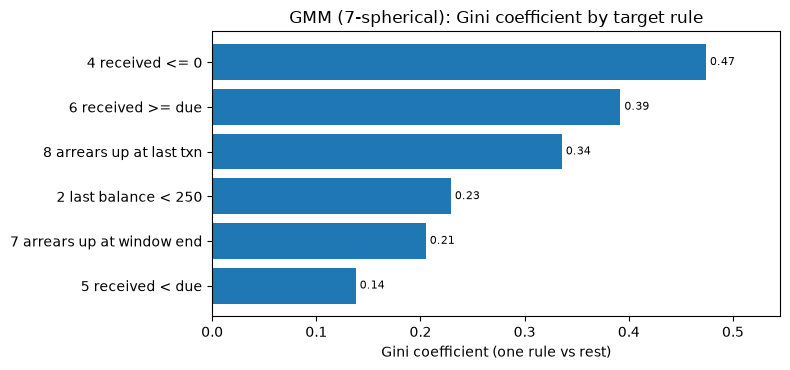

In [9]:
tbl = best_tbl.dropna(subset=["gini"]).sort_values("gini")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(tbl["rule_name"], tbl["gini"])
for i, v in enumerate(tbl["gini"]):
    ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
ax.set_xlabel("Gini coefficient (one rule vs rest)")
ax.set_title(f"{METHOD.upper()} ({best_id}): Gini coefficient by target rule")
ax.set_xlim(0, max(0.1, tbl["gini"].max() * 1.15))
plt.tight_layout(); plt.show()

In [10]:
pd.DataFrame({OBS_ID: obs_ids.to_numpy(), "cluster": best_labels,
              "target_rule": rule_arr}).to_csv(OUT_DIR / f"{METHOD}_best_assignments.csv", index=False)
print("Saved outputs to:", OUT_DIR.resolve())

Saved outputs to: /Users/emmadevilliers/Documents/GitHub/MOR-assignment3/gmm_gini_output
